In [28]:
import pandas as pd
from pathlib import Path

ROOT = Path.cwd().parent

INPUT_FILE = ROOT / 'data' / 'pricing' / 'bedrock_pricing.csv'

In [29]:
df_price = pd.read_csv(INPUT_FILE)

Here we have the prices per model for 1million tokens on output and input. These will be used to quantify the costs of using these models and then extrapolated to the fictional workloads they will be applied to, which helps us better understand the cost at scale. We purposely chose cheap models and simple tasks to keep our personal costs low for this project as we will be paying out of pocket for the bedrock fees.

In [30]:
df_price

,model_name,bedrock_model_pricing_name,region,input_price_usd_per_1m_tokens,output_price_usd_per_1m_tokens
0,nvidia_nemotron_nano_12b,NVIDIA Nemotron Nano 2 VL,US East (N. Virginia) / us-east-1,0.20,0.60
1,nova_lite,Amazon Nova Lite,US East (N. Virginia) / us-east-1,0.06,0.24
2,qwen3_32b,Qwen3 32B,US East (N. Virginia) / us-east-1,0.15,0.60
3,llama_scout_17b,Llama 4 Scout 17B,US East (N. Virginia) / us-east-1,0.17,0.66


First we looked at overall summary scores for the tasks on our key metrics.

In [31]:
df_issue_classification = pd.read_csv(ROOT / 'data' / 'outputs' / 'customer_issue_classification_model_comparison.csv')
df_response_drafting = pd.read_csv(ROOT / 'data' / 'outputs' / 'customer_response_drafting_model_comparison.csv')
df_catalogue_extraction = pd.read_csv(ROOT / 'data' / 'outputs' / 'product_catalogue_extraction_model_comparison.csv')
df_review_summarization = pd.read_csv(ROOT / 'data' / 'outputs' / 'product_review_summarization_model_comparison.csv')

We merge in the pricing data to the task data

In [32]:
df_tasks = pd.concat([df_issue_classification, df_response_drafting, df_catalogue_extraction, df_review_summarization])
df_tasks = df_tasks.merge(df_price[['model_name', 'input_price_usd_per_1m_tokens', 'output_price_usd_per_1m_tokens']], how='left', on='model_name')

In [33]:
df_tasks.head()

,workload,model_name,average_quality_score,successful_evaluations,average_latency_seconds,average_input_tokens,average_output_tokens,input_price_usd_per_1m_tokens,output_price_usd_per_1m_tokens
0,customer_issue_classification,nvidia_nemotron_nano_12b,4.82,25,0.95,585.68,99.36,0.20,0.60
1,customer_issue_classification,nova_lite,4.64,25,0.73,618.80,66.68,0.06,0.24
2,customer_issue_classification,qwen3_32b,4.61,25,0.60,570.04,69.84,0.15,0.60
3,customer_issue_classification,llama_scout_17b,4.56,25,0.95,577.08,102.24,0.17,0.66
4,customer_response_drafting,nova_lite,4.99,25,4.04,1569.48,235.24,0.06,0.24


We then use our pricing data to calculate cost figures for comparison - we use 1 million tasks as our estimate of a high volume workload that a company like amazon might undergo on a daily or weekly basis - this is just a random guess.

In [39]:
def calculate_avg_cost(row):
    input_cost = (row['average_input_tokens'] / 1_000_000) * row['input_price_usd_per_1m_tokens'] 
    output_cost = (row['average_output_tokens'] / 1_000_000) * row['output_price_usd_per_1m_tokens'] 
    return input_cost + output_cost

def calculate_total_cost(row):
    input_cost = (row['average_input_tokens'] / 1_000_000) * row['input_price_usd_per_1m_tokens'] * row['successful_evaluations']
    output_cost = (row['average_output_tokens'] / 1_000_000) * row['output_price_usd_per_1m_tokens']  * row['successful_evaluations']
    return input_cost + output_cost

def calculate_cost_per(row, n=1000000):
    input_cost = (row['average_input_tokens'] / 1_000_000) * row['input_price_usd_per_1m_tokens'] * n
    output_cost = (row['average_output_tokens'] / 1_000_000) * row['output_price_usd_per_1m_tokens']  * n
    return input_cost + output_cost   

df_tasks['avg_cost'] = df_tasks.apply(calculate_avg_cost, axis=1)
df_tasks['total_cost'] = df_tasks.apply(calculate_total_cost, axis=1)
df_tasks['cost_per_1mill'] = df_tasks.apply(calculate_cost_per, axis=1)

In [40]:
df_tasks

,workload,model_name,average_quality_score,successful_evaluations,average_latency_seconds,average_input_tokens,average_output_tokens,input_price_usd_per_1m_tokens,output_price_usd_per_1m_tokens,avg_cost,total_cost,cost_per_100k,cost_per_1mill
0,customer_issue_classification,nvidia_nemotron_nano_12b,4.82,25,0.95,585.68,99.36,0.20,0.60,0.000177,0.004419,17.67520,176.7520
1,customer_issue_classification,nova_lite,4.64,25,0.73,618.80,66.68,0.06,0.24,0.000053,0.001328,5.31312,53.1312
2,customer_issue_classification,qwen3_32b,4.61,25,0.60,570.04,69.84,0.15,0.60,0.000127,0.003185,12.74100,127.4100
3,customer_issue_classification,llama_scout_17b,4.56,25,0.95,577.08,102.24,0.17,0.66,0.000166,0.004140,16.55820,165.5820
4,customer_response_drafting,nova_lite,4.99,25,4.04,1569.48,235.24,0.06,0.24,0.000151,0.003766,15.06264,150.6264
5,customer_response_drafting,qwen3_32b,4.99,25,1.04,1332.72,199.00,0.15,0.60,0.000319,0.007983,31.93080,319.3080
6,customer_response_drafting,nvidia_nemotron_nano_12b,4.97,25,1.38,1412.40,198.56,0.20,0.60,0.000402,0.010040,40.16160,401.6160
7,customer_response_drafting,llama_scout_17b,4.96,25,1.42,1324.32,193.64,0.17,0.66,0.000353,0.008823,35.29368,352.9368
8,product_catalogue_extraction,llama_scout_17b,4.51,25,1.43,1278.28,310.56,0.17,0.66,0.000422,0.010557,42.22772,422.2772
9,product_catalogue_extraction,nvidia_nemotron_nano_12b,4.28,25,1.27,1358.08,215.40,0.20,0.60,0.000401,0.010021,40.08560,400.8560


Here we install seaborn to help with visualizations

In [ ]:
#!pip install matplotlib seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)


The visualizations tell an interesting story. Mainly that the spread in evaluation quality is actually quite narrow. This is likely because the tasks were too simple and the ability for even our cheap models to do the task was trivial. The other aspect worth exploring is that our judge model was also a cheap model - which could mean it just didn't do a good job as a judge and thought every model performed well. A follow up for next milestone is to use a medium tier model for the evaluation of the budget models we used.

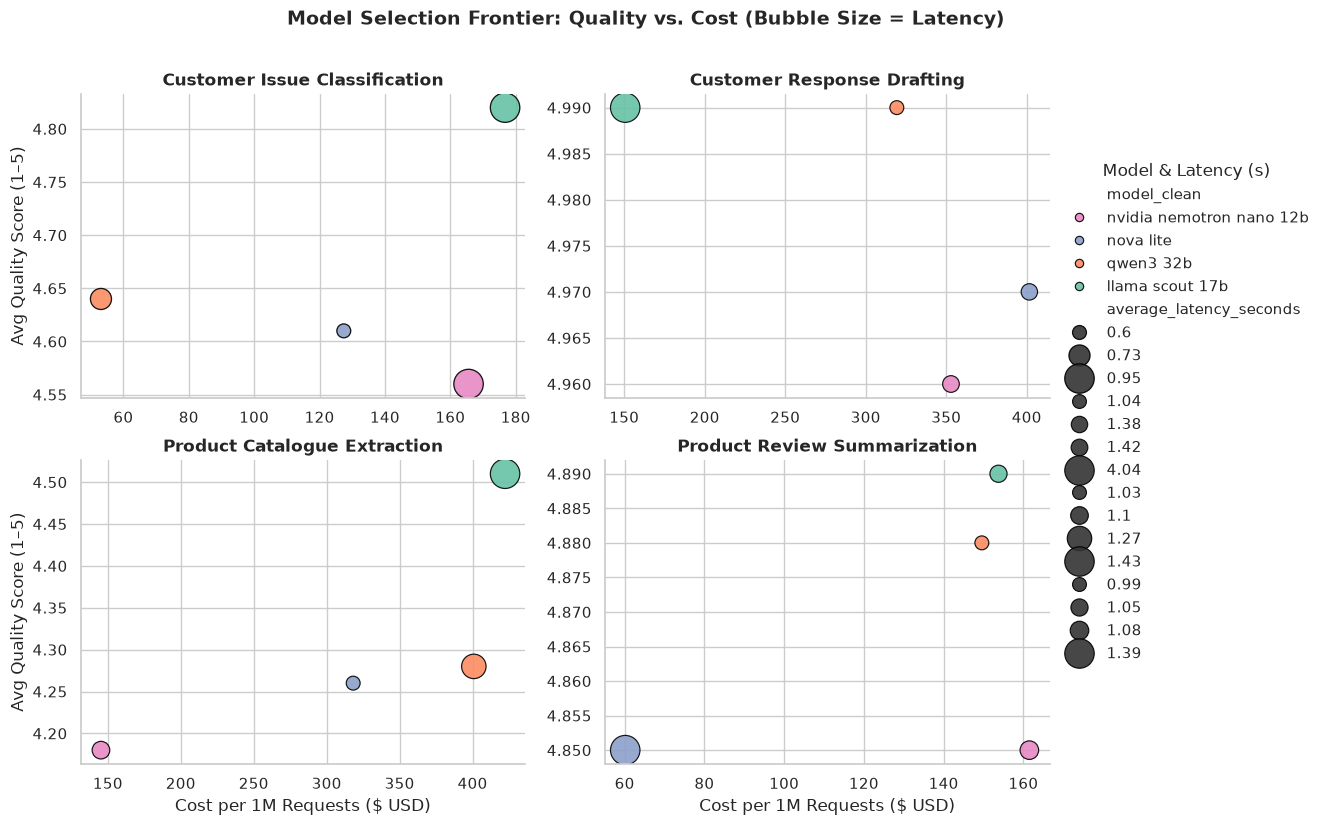

In [49]:
import matplotlib.pyplot as plt
import seaborn as sns

df_tasks["workload_clean"] = df_tasks["workload"].str.replace("_", " ").str.title()
df_tasks["model_clean"] = df_tasks["model_name"].str.replace("_", " ")

sns.set_theme(style="whitegrid", context="notebook")
palette = sns.color_palette("Set2", n_colors=df_tasks["model_clean"].nunique())

g = sns.FacetGrid(
    df_tasks,
    col="workload_clean",
    col_wrap=2,
    height=4.2,
    aspect=1.3,
    sharex=False,
    sharey=False,
)
g.map_dataframe(
    sns.scatterplot,
    x="cost_per_1mill",
    y="average_quality_score",
    hue="model_clean",
    size="average_latency_seconds",
    sizes=(100, 450),
    palette=palette,
    alpha=0.9,
    edgecolor="black",
)
g.set_titles("{col_name}", fontweight="bold")
g.set_axis_labels("Cost per 1M Requests ($ USD)", "Avg Quality Score (1–5)")
g.add_legend(title="Model & Latency (s)")
plt.subplots_adjust(top=0.88)
g.fig.suptitle(
    "Model Selection Frontier: Quality vs. Cost (Bubble Size = Latency)",
    fontsize=14,
    fontweight="bold",
)
plt.savefig("1_cost_quality_frontier.png", dpi=300, bbox_inches="tight")
plt.show()

Latency was quite uniform in most cases, excluding for some reason Nova lite had a long response time for customer response drafting. Perhaps the model struggled with this task as it may have been more taxing - which again suggests perhaps it might have not been up to the task of being a judge.

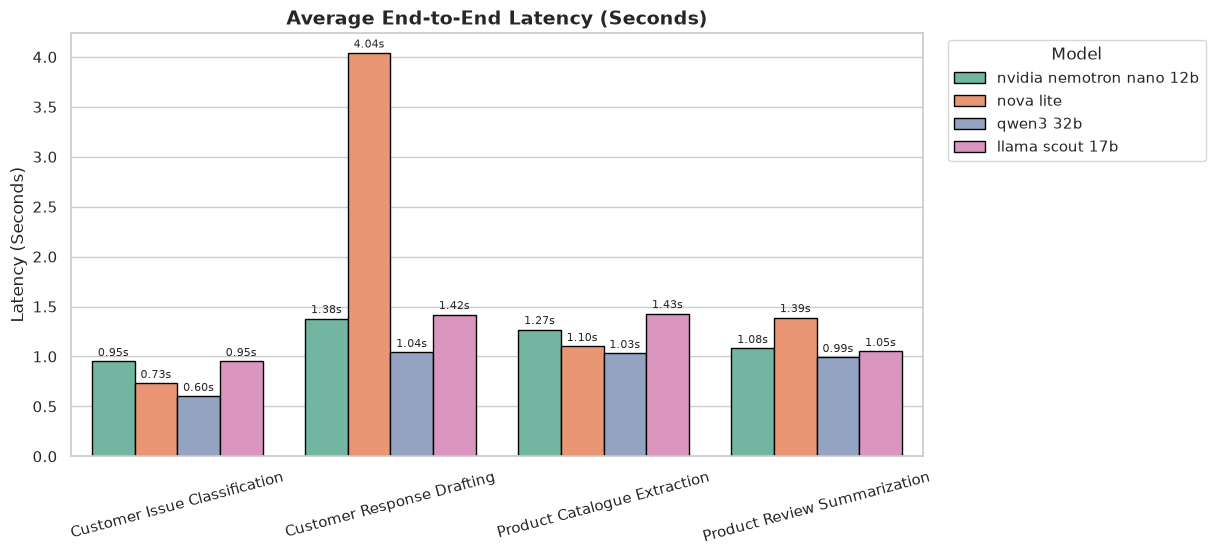

In [51]:
plt.figure(figsize=(11, 5.5))
ax = sns.barplot(data=df_tasks, x="workload_clean", y="average_latency_seconds", hue="model_clean", palette=palette, edgecolor="black")
plt.title("Average End-to-End Latency (Seconds)", fontsize=14, fontweight="bold")
plt.xlabel("")
plt.ylabel("Latency (Seconds)")
plt.xticks(rotation=15)
plt.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
for container in ax.containers:
    ax.bar_label(container, fmt="%.2fs", fontsize=8, padding=2)
plt.savefig("2_latency.png", dpi=300, bbox_inches="tight")
plt.show()

The cost at scale for the models showed that Nova lite was the cheapest by far on any tasks and the other models had over double the at scale costs. This begs the question - is the additional cost worth the potential lift in quality from these other models?

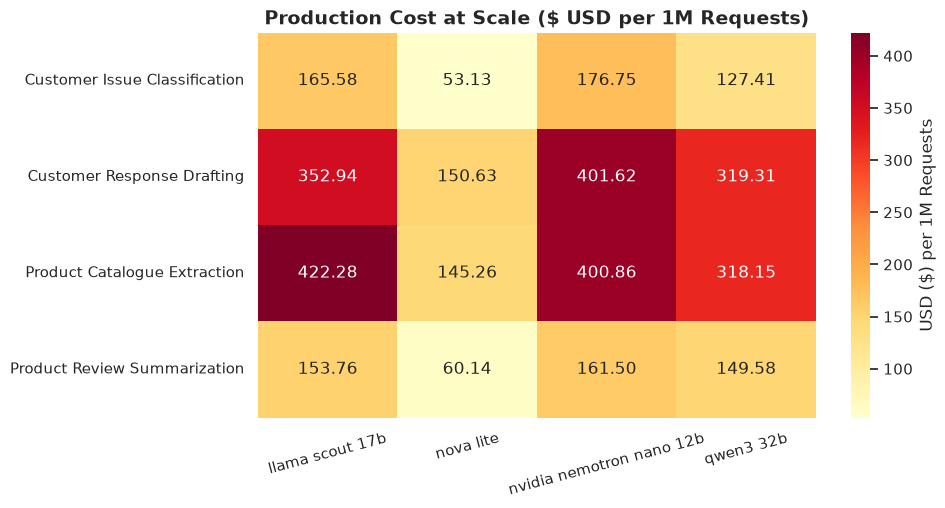

In [52]:
pivot_cost = df_tasks.pivot(index="workload_clean", columns="model_clean", values="cost_per_1mill")
plt.figure(figsize=(9, 5))
sns.heatmap(pivot_cost, annot=True, fmt=".2f", cmap="YlOrRd", cbar_kws={"label": "USD ($) per 1M Requests"})
plt.title("Production Cost at Scale ($ USD per 1M Requests)", fontsize=14, fontweight="bold")
plt.xlabel("")
plt.ylabel("")
plt.xticks(rotation=15)
plt.savefig("3_cost_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

Next we look at the distributions of the evaluations to better understand the variation observed in the metrics and investigate outliers.

In [58]:
df_full = pd.read_csv(ROOT / 'data' / 'outputs' / 'all_workloads_distributions.csv')

In [59]:
df_full.head()

,workload,model_name,input_data,generated_output,overall_score,overall_comment,judge_model,judge_latency_seconds,latency_seconds,input_tokens,...,Empathy_score,Empathy_reason,Professionalism_score,Professionalism_reason,Helpfulness_score,Helpfulness_reason,Policy Compliance_score,Policy Compliance_reason,Factuality_score,Factuality_reason
0,product_catalogue_extraction,nova_lite,"{""brand"": ""[{'language_tag': 'en_CA', 'value':...","```json\n{\n ""product_id"": ""B07SX8KYL3"",\n ...",4.6,The model performed excellently in extracting ...,nova_lite,1.9158,1.2314,1949,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,product_catalogue_extraction,nvidia_nemotron_nano_12b,"{""brand"": ""[{'language_tag': 'en_CA', 'value':...","{\n ""product_id"": ""B07SX8KYL3"",\n ""produ...",4.4,The model performed well in accurately extract...,nova_lite,1.7072,1.4529,1681,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,product_catalogue_extraction,qwen3_32b,"{""brand"": ""[{'language_tag': 'en_CA', 'value':...","{\n ""product_id"": ""B07SX8KYL3"",\n ""produ...",4.4,The model performed excellently in terms of ac...,nova_lite,1.5173,1.1592,1570,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,product_catalogue_extraction,llama_scout_17b,"{""brand"": ""[{'language_tag': 'en_CA', 'value':...",Here is the extracted product information in t...,4.6,"The model-generated output is highly accurate,...",nova_lite,1.8027,1.1985,1561,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,product_catalogue_extraction,nova_lite,"{""brand"": ""[{'language_tag': 'en_CA', 'value':...","```json\n{\n ""product_id"": ""B07YF2L8YK"",\n ...",4.2,The model performed well in extracting accurat...,nova_lite,1.5617,1.2085,1039,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Of interest is the judges reasoning for giving highest or lowest marks across the various tasks. There does seem to be legitimate reasoning for giving lower scores. A human review should verify whether these are warrented and if the judge was up to the task.

In [66]:
cols = ["workload", "model_name", "overall_score", "overall_comment"]

# Ensure scores are numeric
df_full["overall_score"] = pd.to_numeric(
    df_full["overall_score"], errors="coerce"
)

# Sort by score, highest first
df_sorted = df_full.sort_values("overall_score", ascending=False)

# Top 5 evaluations per workload
top_5 = (
    df_sorted.groupby("workload", sort=False)
    .head(5)[cols]
    .reset_index(drop=True)
)

# Bottom 5 evaluations per workload
bottom_5 = (
    df_sorted.groupby("workload", sort=False)
    .tail(5)[cols]
    .sort_values(["workload", "overall_score"])
    .reset_index(drop=True)
)

# Show full text in columns without truncation
pd.set_option("display.max_colwidth", None)

# Display all columns
pd.set_option("display.max_columns", None)

print("TOP 5 PER WORKLOAD")
display(top_5)

print("BOTTOM 5 PER WORKLOAD")
display(bottom_5)

TOP 5 PER WORKLOAD


,workload,model_name,overall_score,overall_comment
0,customer_response_drafting,llama_scout_17b,5.0,"The model-generated output effectively addresses the customer's concern with empathy, professionalism, and helpfulness, while adhering to policy and factual accuracy."
1,customer_response_drafting,qwen3_32b,5.0,"The model-generated output effectively addresses the customer's concern with empathy, professionalism, and helpfulness, while also adhering to company policy and factual accuracy."
2,customer_response_drafting,nvidia_nemotron_nano_12b,5.0,"The model-generated output effectively addresses the customer's concern with empathy, professionalism, and clarity, while adhering to company policy and factual accuracy."
3,customer_response_drafting,nova_lite,5.0,"The model-generated output effectively addresses the customer's concern with empathy, professionalism, and helpfulness, while adhering to company policy and factual accuracy."
4,customer_response_drafting,llama_scout_17b,5.0,"The model-generated output effectively addresses the customer's concerns, demonstrates empathy, uses professional language, provides helpful next steps, complies with company policies, and is factually accurate."
5,product_catalogue_extraction,llama_scout_17b,5.0,"The model-generated output is excellent, meeting all evaluation criteria with high accuracy, completeness, relevance, hallucination control, and format compliance."
6,product_review_summarization,llama_scout_17b,5.0,"The generated output is highly accurate, complete, and concise, capturing the essence of the original review without introducing any unsupported information."
7,product_review_summarization,qwen3_32b,5.0,"The model-generated output is excellent, accurately summarizing the key points of the review with no inaccuracies or unsupported information."
8,product_review_summarization,nova_lite,5.0,"The model-generated output is excellent, accurately and concisely summarizing the key points of the original review without introducing any unsupported information."
9,product_review_summarization,qwen3_32b,5.0,"The model-generated output is highly accurate, complete, and concise, capturing the essence of the original review without introducing any unsupported information."


BOTTOM 5 PER WORKLOAD


,workload,model_name,overall_score,overall_comment
0,customer_issue_classification,nova_lite,2.00,"The model failed to correctly classify the issue and provided an incorrect explanation, but it did follow the required output format."
1,customer_issue_classification,qwen3_32b,2.00,"The model failed to correctly classify the issue and provided an incorrect explanation, but it did follow the required JSON format."
2,customer_issue_classification,qwen3_32b,2.40,"The model's output has some issues with classification accuracy and information handling, but it correctly identifies the urgency and follows the required format."
3,customer_issue_classification,llama_scout_17b,2.60,The model's output is partially correct but has significant issues with classification accuracy and reasoning quality due to an incorrect assumption about the product.
4,customer_issue_classification,llama_scout_17b,4.00,"The model's response is well-structured and accurately classifies the issue, though it could improve in handling discrepancies between product details and the issue."
5,customer_response_drafting,nvidia_nemotron_nano_12b,4.67,The model-generated output is highly effective in addressing the customer's concerns with professionalism and helpfulness. It slightly falls short in factuality due to the lack of exact dimensions for phone compatibility.
6,customer_response_drafting,nvidia_nemotron_nano_12b,4.67,"The model-generated output is highly effective in addressing the customer's questions with clear, professional, and factual information. The only minor deduction is for the slight lack of empathy, as the response could be slightly more personalized."
7,customer_response_drafting,llama_scout_17b,4.67,"The model-generated output is highly effective in addressing the customer's query with relevance, empathy, professionalism, and factual accuracy. It slightly lacks in providing additional actionable next steps, which could further enhance the customer's experience."
8,customer_response_drafting,nova_lite,4.67,"The model-generated output is highly effective in addressing the customer's concern with empathy, professionalism, and factual accuracy. The only minor area for improvement is providing more specific next steps, such as contact information for the support team."
9,customer_response_drafting,llama_scout_17b,4.83,"The response is well-crafted, addressing the customer's questions with clarity and professionalism. It could be slightly improved by providing more specific recommendations for reaching the printer."


Based on the distributions observed across the tasks we can see we have actual spread across the product catalogue extraction and customer issue classification. product category extraction had more of a normal spread while product catalogue extraction was more impacted by outliers. This is perhaps to the rather simple, almost binarized nature of the product catalogue task.

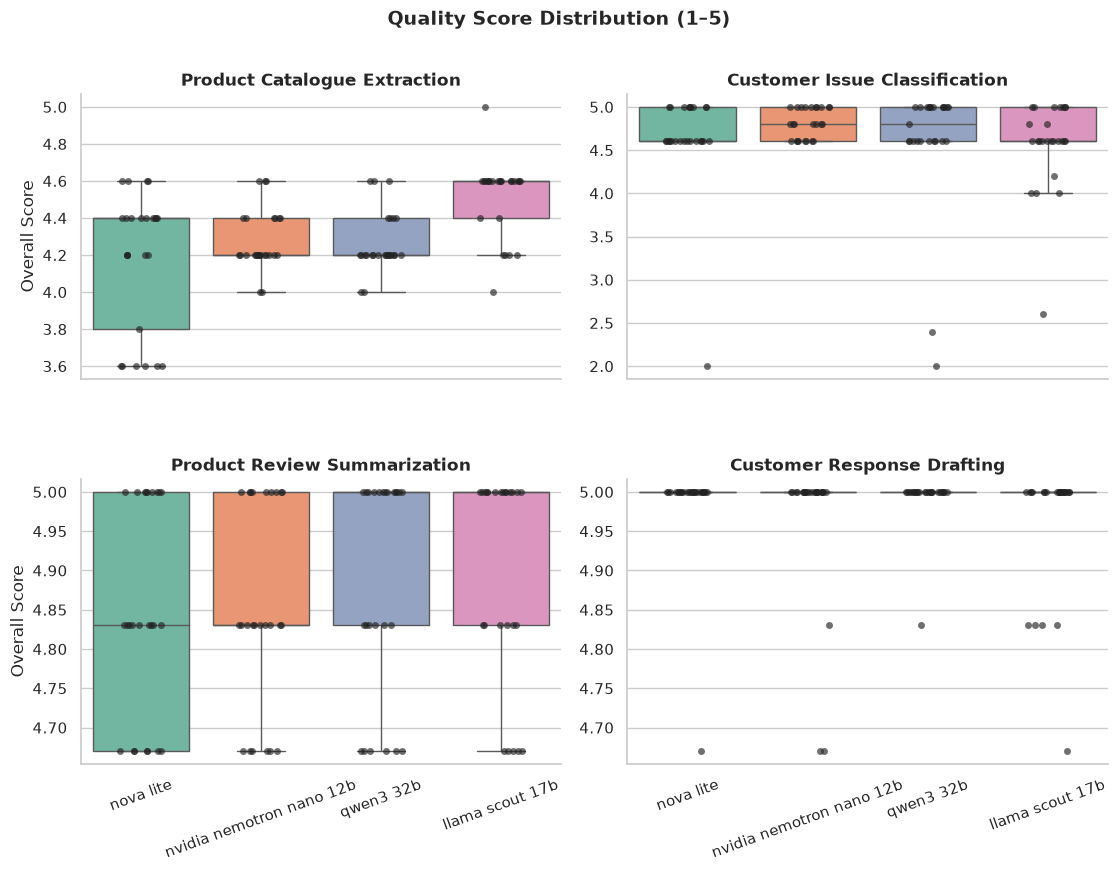

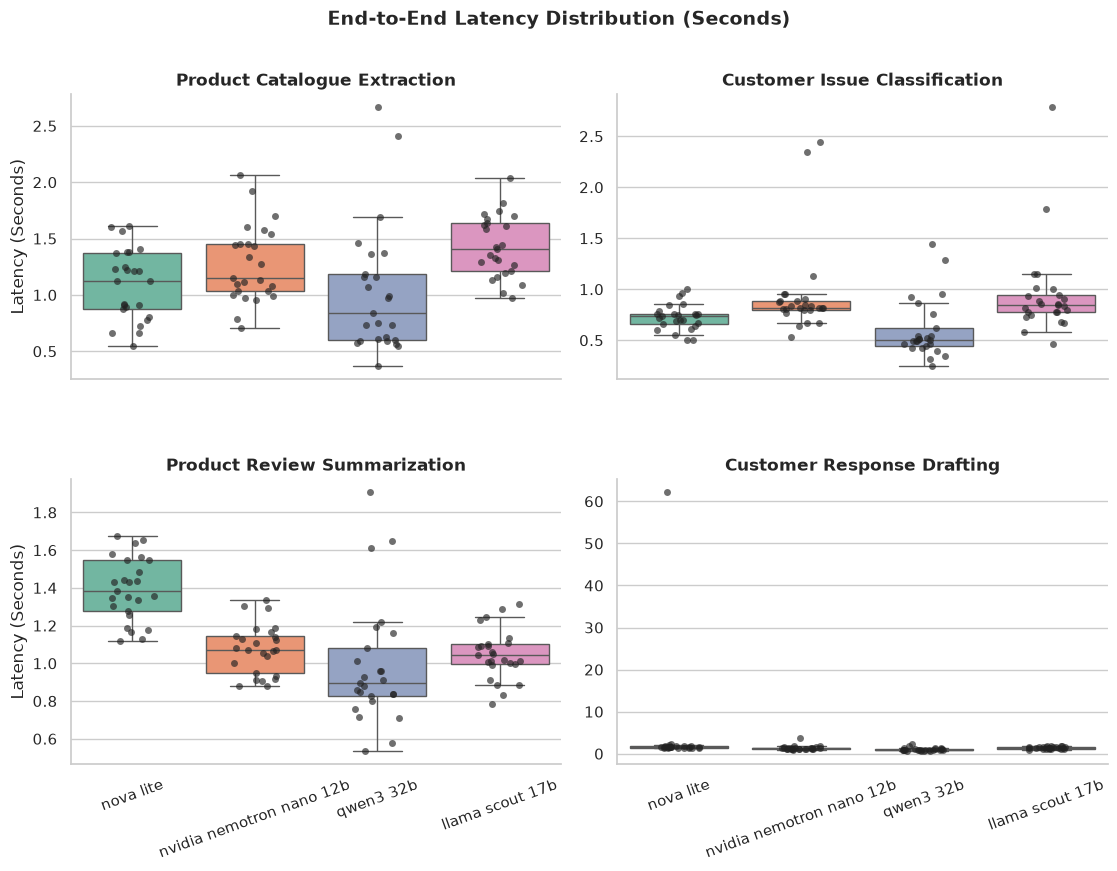

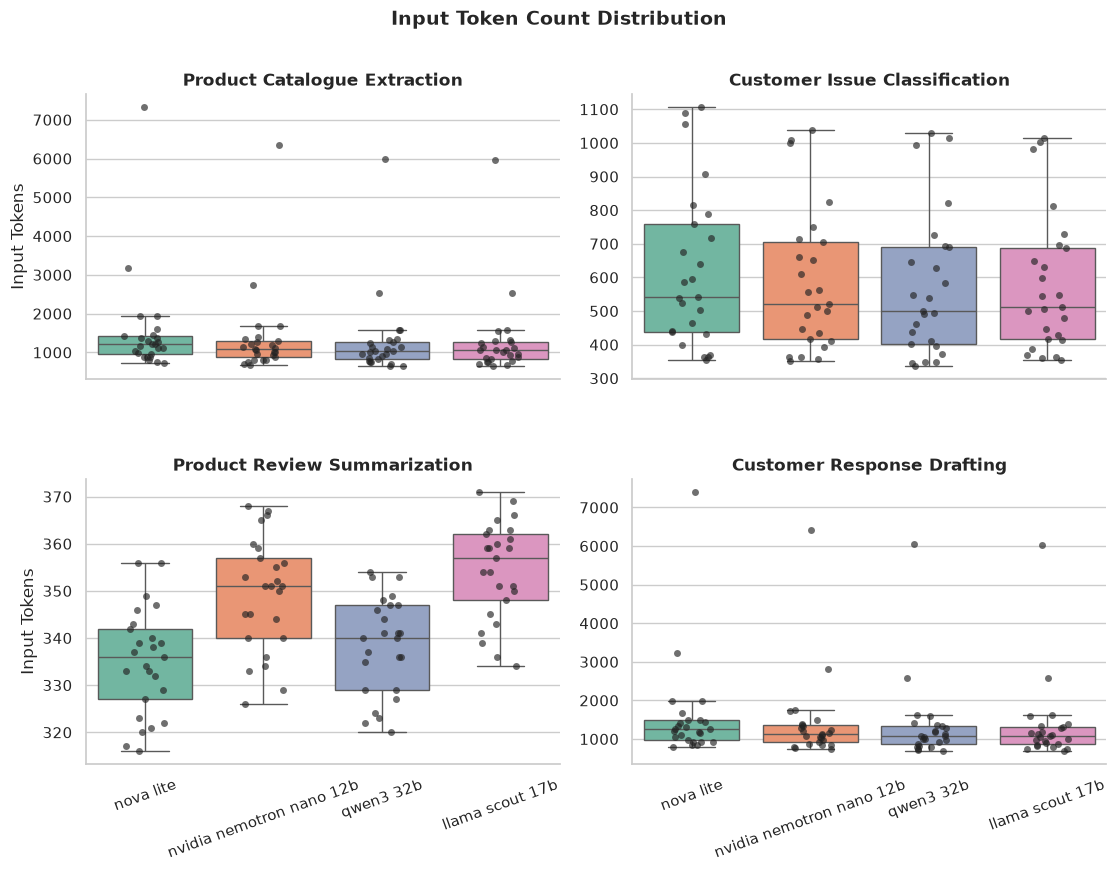

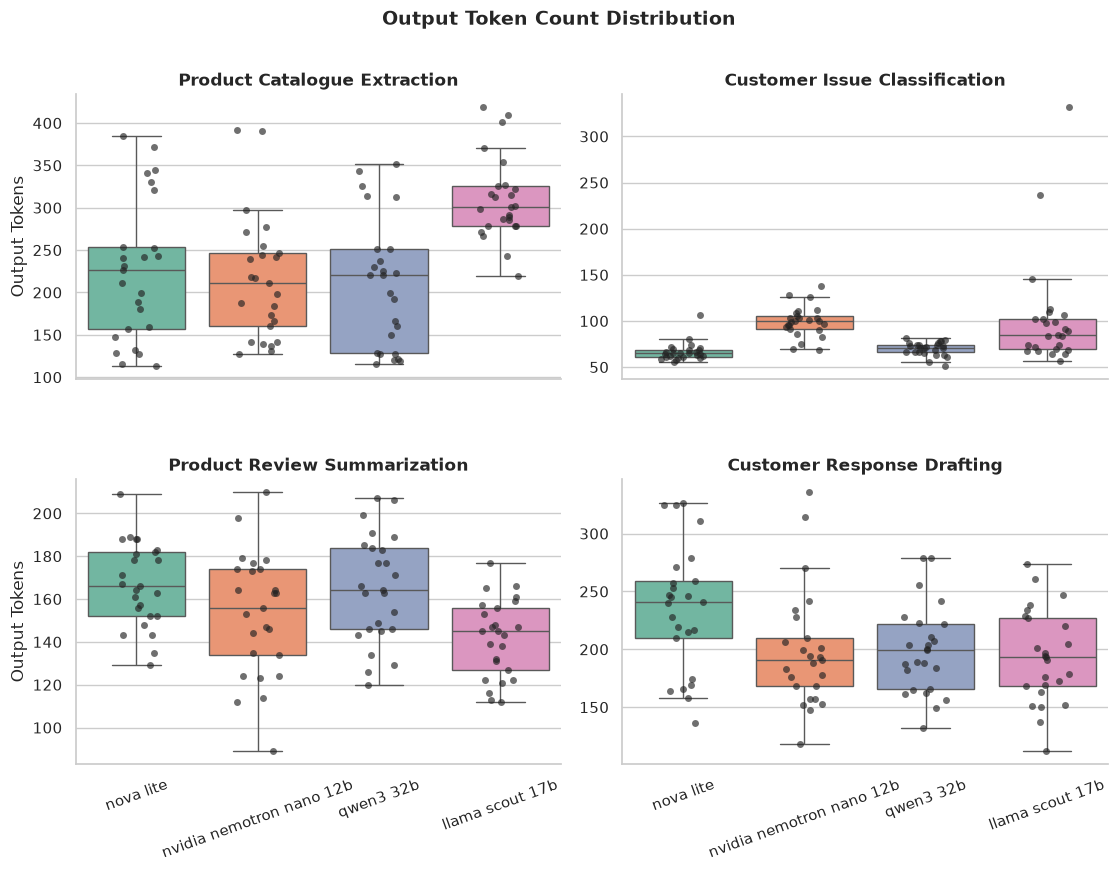

In [60]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Clean labels for readable chart titles and legends
df_plot = df_full.copy()
df_plot["workload_clean"] = df_plot["workload"].str.replace("_", " ").str.title()
df_plot["model_clean"] = df_plot["model_name"].str.replace("_", " ")

sns.set_theme(style="whitegrid", context="notebook")
palette = sns.color_palette("Set2", n_colors=df_plot["model_clean"].nunique())

# Define the 4 raw metrics to visualize
metrics = [
    ("overall_score", "Quality Score Distribution (1–5)", "Overall Score"),
    ("latency_seconds", "End-to-End Latency Distribution (Seconds)", "Latency (Seconds)"),
    ("input_tokens", "Input Token Count Distribution", "Input Tokens"),
    ("output_tokens", "Output Token Count Distribution", "Output Tokens"),
]

# Generate one multi-panel figure per metric (split by workload)
for col, title, ylabel in metrics:
    g = sns.catplot(
        data=df_plot,
        x="model_clean",
        y=col,
        hue="model_clean",
        col="workload_clean",
        col_wrap=2,
        kind="box",
        palette=palette,
        height=4.2,
        aspect=1.35,
        sharey=False,       # Allows each workload to scale to its own range
        showfliers=False,   # Hides duplicate outlier diamonds since stripplot shows all points
        legend=False,
    )

    # Overlay individual evaluation runs (25 dots per model)
    g.map_dataframe(
        sns.stripplot,
        x="model_clean",
        y=col,
        color="#222222",
        size=5,
        jitter=0.18,
        alpha=0.65,
    )

    g.set_titles("{col_name}", fontweight="bold", fontsize=11)
    g.set_axis_labels("", ylabel)

    # Rotate model names on x-axis so they never overlap
    for ax in g.axes.flat:
        ax.tick_params(axis="x", rotation=20)

    plt.subplots_adjust(top=0.88, hspace=0.35)
    g.fig.suptitle(title, fontsize=14, fontweight="bold")
    plt.show()